# トークン長の分布を調べて max_length を決める

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/05_subword/token_length_dist.ipynb)

NLP クックブック 05-12 ／ サブワードとトークナイザ

データセットのトークン長がどのくらいかを調べて、切り詰め長 (`max_length`) を根拠をもって決めたい。

In [1]:
import numpy as np
import nltk
nltk.download("movie_reviews", quiet=True)
from nltk.corpus import movie_reviews
from transformers import AutoTokenizer

texts = [movie_reviews.raw(f) for f in movie_reviews.fileids()[:500]]
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
lengths = np.array([len(ids) for ids in tokenizer(texts, truncation=False)["input_ids"]])

print("平均", lengths.mean().round(1), "中央値", np.median(lengths), "最大", lengths.max())
for p in [50, 90, 95, 99]:
    print(f"{p} パーセンタイル: {np.percentile(lengths, p):.0f}")
for L in [128, 256, 512]:
    print(f"max_length={L}: {(lengths <= L).mean():.1%} が切り詰めなしで収まる")

平均 801.8 中央値 754.5 最大 2436
50 パーセンタイル: 754
90 パーセンタイル: 1207
95 パーセンタイル: 1428
99 パーセンタイル: 1774
max_length=128: 0.0% が切り詰めなしで収まる
max_length=256: 1.8% が切り詰めなしで収まる
max_length=512: 17.2% が切り詰めなしで収まる


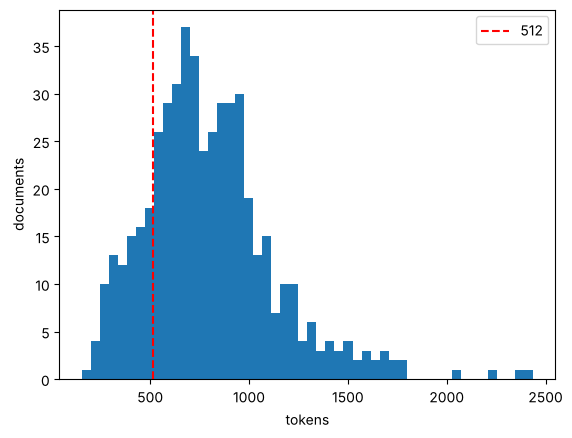

In [2]:
import matplotlib.pyplot as plt

plt.hist(lengths, bins=50)
plt.axvline(512, color="red", linestyle="--", label="512")
plt.xlabel("tokens"); plt.ylabel("documents"); plt.legend(); plt.show()

- 95 パーセンタイルあたりを `max_length` にするのが定番。長い文書が多いなら、先頭 + 末尾を残す・分割して集約するなどを検討する。